## Info 290T: Continual Learning - Final Project

This is a simple notebook analyzing the accuracy of the outputs of our continual learning system. The base level of system is designed to take CSVs of user transactions and predict the categories of these transactions, such as "Rent" or "Groceries," as well as store embeddings of them using a module called distilbert. The continual learning portion of the model tries to track and remember these changes, but without overriding all previous categorizations to the point of catastrophic forgetting.

#### Initial Baseline (Frozen Model, distilbert categorizations only)

First, we need to calculate the accuracy of this baseline model. This will be the point to which we can make comparisons, using other versions of the model with continual learning implemented.

In [4]:
import os
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
baseline_df = pd.read_csv('frozen_predictions_2026.csv')
print(baseline_df.head())

   txn_id        date                                        description  \
0       1  2026-01-01             UC BERKELEY PAYROLL PPD ID: 1946000123   
1       2  2026-01-01  Zelle payment to Bayview Property Mgmt JPM99ES...   
2       3  2026-01-02           Zelle payment to Ashley Kim JPM99U2T011V   
3       4  2026-01-02                           CAFFE STRADA BERKELEY CA   
4       5  2026-01-03                              PHILZ COFFEE BERKELEY   

    amount note true_category    predicted  confidence  correct  
0  1350.00  NaN        Income       Income       1.000     True  
1 -1225.00  NaN       Housing     Transfer       0.996    False  
2  -275.00  NaN       Housing     Transfer       0.990    False  
3    -6.96  NaN   Restaurants  Restaurants       0.998     True  
4    -7.49  NaN   Restaurants  Restaurants       1.000     True  


In [12]:
# What's the overall accuracy? 

print("Overall baseline accuracy: ", round(baseline_df[baseline_df["correct"] == True].shape[0] / baseline_df.shape[0] * 100, 2), "%")

Overall baseline accuracy:  41.59 %


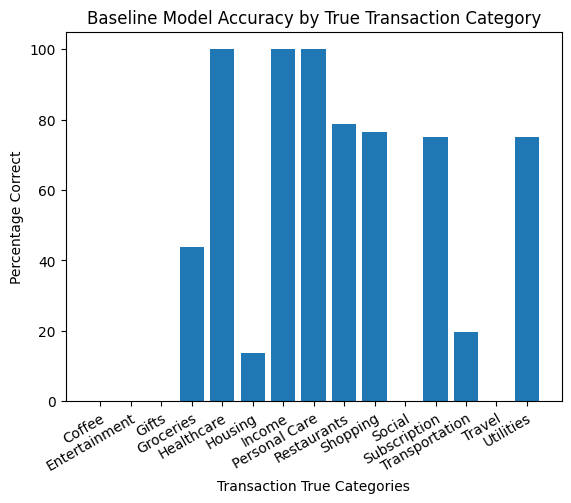

In [43]:
# What does accuracy look like per category? (based on the true assigned category)

baseline_correct = baseline_df.groupby('true_category').sum()["correct"]
baseline_grouped = baseline_correct.to_frame().reset_index()
baseline_total = baseline_df.groupby('true_category').count()["txn_id"].to_frame().reset_index()
baseline_grouped["total"] = baseline_total["txn_id"]
baseline_grouped["percentage_correct"] = round(baseline_grouped["correct"] / baseline_grouped["total"] * 100, 2)

fig, ax = plt.subplots()
ax.bar(baseline_grouped["true_category"], baseline_grouped["percentage_correct"])
plt.title("Baseline Model Accuracy by True Transaction Category")
plt.xlabel("Transaction True Categories")
ax.tick_params(axis="x", labelrotation=30)
plt.setp(ax.get_xticklabels(), ha="right", rotation_mode="anchor")
plt.ylabel("Percentage Correct")
plt.show()

In [44]:
baseline_grouped

,true_category,correct,total,percentage_correct
0,Coffee,0,105,0.00
1,Entertainment,0,15,0.00
2,Gifts,0,1,0.00
3,Groceries,25,57,43.86
4,Healthcare,6,6,100.00
5,Housing,3,22,13.64
6,Income,24,24,100.00
7,Personal Care,10,10,100.00
8,Restaurants,123,156,78.85
9,Shopping,26,34,76.47


The frozen base model currently struggles to accurately categorize transactions for coffee, entertainment, housing, social, transportation, and occasionally groceries. This is likely due to these categories not being existing categories in the distilbert module. When implementing the continual learning portion, it would be great to see an increase in accurate categorizations for these categories as long as accuracy doesn't significantly decrease for others. 